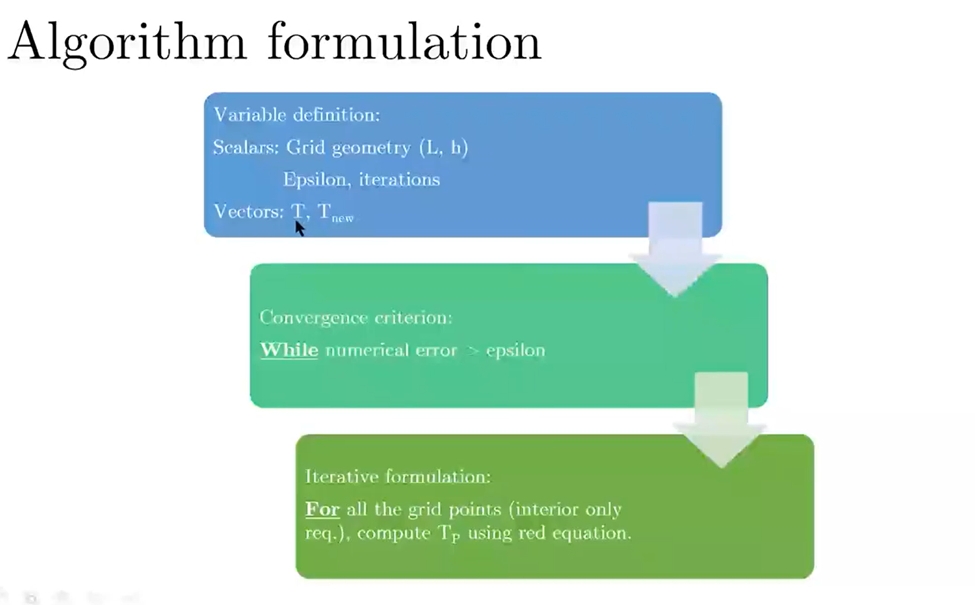

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Scalar values

In [2]:
# No of grid poins
N = 21

# Domain size
L = 1

# Corresponding grid spacing
h = np.float64(L/(N-1)) 

# Thermal conductivity
k = 0.1

# cross section area
A = 0.001

# Iteration number
iterations = 0

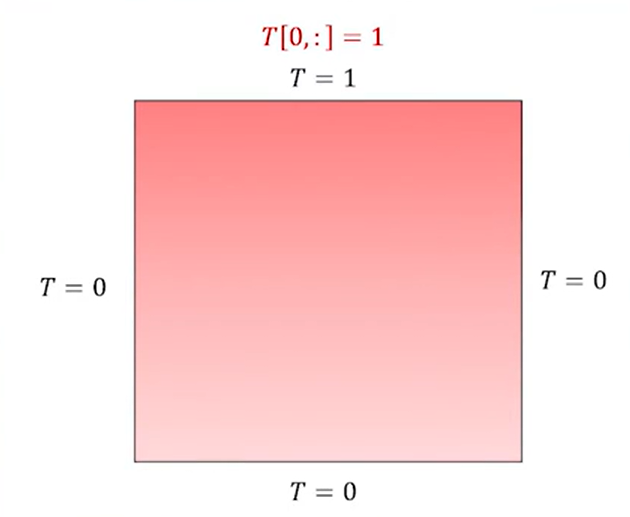

# temprature field initializing

In [3]:
# initializing temprature field
T = np.zeros((N, N))
T[0, :] = 1.

# Initializing iterated temprature
T_new = np.zeros((N, N))
T_new[0, :] = 1.

# error related variables
epsilon = 1.E-8
numerical_error = 1

# Plot for numerical error

In [4]:
plt.figure(10)

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

# Computation

In [11]:
while numerical_error > epsilon:
    # Computing for all interior points
    for i in range(1, N-1):
        for j in range(1, N-1):
            a_e = np.float64(k*A/h)
            a_w = np.float64(k*A/h)
            a_n = np.float64(k*A/h)
            a_s = np.float64(k*A/h)
            a_p = a_e + a_w + a_n + a_s
            T_new[i, j] = (a_e*T[i, j+1] + a_w*T[i, j-1] + a_n*T[i-1, j] + a_s*T[i+1, j])/a_p
           
    # Resetting the numerical error and recalculate
    numerical_error = 0
    for i in range(1, N-1):
        for j in range(1, N-1):
            numerical_error = numerical_error + abs(T[i, j]-T_new[i, j])
        
    # Iteration advancement and reassignment
    iterations = iterations + 1
    T = T_new.copy()

    # PLOTTING NUMERICAL ERROR
    if iterations % 1000 == 0:
        plt.figure(10)
        plt.semilogy(iterations, numerical_error, 'ko')
        plt.pause(0.01)


In [12]:
print("The number of iterations is: ", iterations)

The number of iterations is:  1471


In [13]:
print("The final numerical error value is: ", numerical_error)

The final numerical error value is:  9.899490700272795e-09


In [14]:
print("Final temperature field is: ", T)

Final temperature field is:  [[1.         1.         1.         1.         1.         1.
  1.         1.         1.         1.         1.         1.
  1.         1.         1.         1.         1.         1.
  1.         1.         1.        ]
 [0.         0.49725593 0.69212171 0.78220467 0.8300843  0.85824125
  0.87585429 0.88712542 0.89415072 0.89801647 0.89925197 0.89801647
  0.89415072 0.88712542 0.87585429 0.85824125 0.8300843  0.78220467
  0.69212171 0.49725593 0.        ]
 [0.         0.29690203 0.48902625 0.60661266 0.67989128 0.72702642
  0.7580505  0.77849668 0.79146098 0.79866319 0.80097494 0.79866319
  0.79146098 0.77849668 0.7580505  0.72702642 0.67989128 0.60661266
  0.48902625 0.29690203 0.        ]
 [0.         0.20132592 0.36046859 0.47532845 0.55584174 0.61192264
  0.65082461 0.67734982 0.69453332 0.70420038 0.70732141 0.70420038
  0.69453332 0.67734982 0.65082461 0.61192264 0.55584174 0.47532845
  0.36046859 0.20132592 0.        ]
 [0.         0.14793307 0.27619375 

# Plotting results

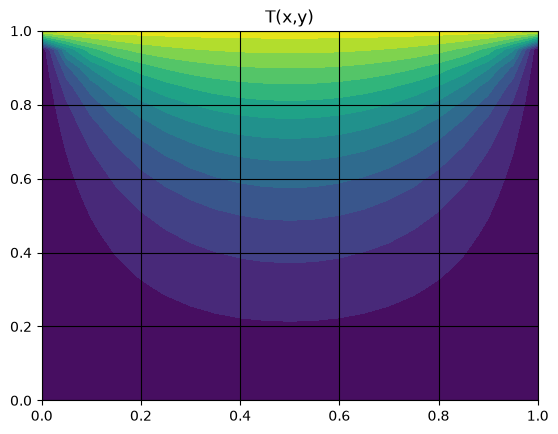

In [15]:
# Defining the position vector fromindices
x_dom = np.arange(N)*h
y_dom = L - np.arange(N)*h
[X, Y] = np.meshgrid(x_dom, y_dom)

# Plotting the variation as a contour plot
plt.figure(10)
plt.contourf(X, Y, T, 12)

#Displaying gridlines
plt.grid(True, color='k')

# Labelling and providing a title to the plot
plt.title("T(x,y)")

# Showing the plot on screen
plt.show()